In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition = fetch_ucirepo(id=544) 


# data (as pandas dataframes) 
df = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.features 
y = estimation_of_obesity_levels_based_on_eating_habits_and_physical_condition.data.targets 
  

In [4]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")


# Description du dataset – Estimation of Obesity Levels Based on Eating Habits and Physical Condition

## 1. Présentation générale

Ce dataset porte sur l'estimation des niveaux d'obésité chez des individus originaires de trois pays d'Amérique latine : le Mexique, le Pérou et la Colombie.

Il a été constitué afin d'étudier les relations entre les habitudes alimentaires, les comportements physiques et les caractéristiques individuelles pouvant être associées aux différents niveaux d'obésité.


## 2. Description des variables

Le dataset comprend des variables relatives aux caractéristiques individuelles, aux habitudes alimentaires et aux comportements physiques.

| Variable | Description |
|---|---|
| `Gender` | Sedfe de l'individu. |
| `Age` | Âge de l'individu. |
| `Height` | Taille de l'individu. |
| `Weight` | Poids de l'individu. |
| `family_history_with_overweight` | Indique si l'individu possède des antécédents familiaux de surpoids. |
| `FAVC` | Indique si l'individu consomme fréquemment des aliments très caloriques. |
| `FCVC` | Fréquence de consommation de légumes. |
| `NCP` | Nombre de repas principaux consommés quotidiennement. |
| `CAEC` | Fréquence de consommation de nourriture entre les repas. |
| `SMOKE` | Indique si l'individu fume. |
| `CH2O` | Quantité d'eau consommée quotidiennement. |
| `SCC` | Indique si l'individu surveille son apport calorique. |
| `FAF` | Fréquence de pratique d'une activité physique. |
| `TUE` | Temps quotidien passé devant les écrans. |
| `CALC` | Fréquence de consommation d'alcool. |
| `MTRANS` | Moyen de transport habituellement utilisé. |
| `NObeyesdad` | Catégorie correspondant au niveau d'obésité de l'individu. |


## 3. Objectif du clustering

Dans le cadre d'une étude non supervisée, ce dataset permet d'identifier des groupes d'individus présentant des habitudes alimentaires et des comportements physiques similaires.

L'objectif est de découvrir différents profils comportementaux, puis d'étudier leur relation avec les catégories de poids définies dans `NObeyesdad`.

Cette analyse peut notamment permettre de mieux comprendre les similitudes entre les individus en fonction de leurs habitudes de vie et de leurs caractéristiques physiques.

## 4. Source du dataset

[UCI Machine Learning Repository – Estimation of Obesity Levels Based on Eating Habits and Physical Condition](https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition)

    

In [4]:
# affichage du dataset
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation


In [6]:
# dimension du dataset
df.shape

(2111, 16)

In [7]:
#info du dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

### <font color = 'yellow'>Exploration et preparation des données<font>


In [8]:
#verifier les doublons
df.duplicated().sum()

np.int64(24)

In [9]:
#suppression des doublons
df = df.drop_duplicates()

In [10]:
#verifier les doublons
df.duplicated().sum()

np.int64(0)

### <font color = 'yellow'>EXploration et preparation des données<font>

In [11]:
# renommer les index
df.index = ['individu' + str(i+1) for i in range(len(df))]
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
individu1,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation
individu2,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation
individu3,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation
individu4,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking
individu5,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation


##### <font color = 'yellow'> Selection des variables catégorielles et quantitatives

In [12]:
#selection des variables categorielles
cat_data = df.select_dtypes('object')

In [13]:
#selection des variables quantitative
quant_data = df.select_dtypes(exclude='object')

###### <font color = 'bisque'> Edfploration des variables catégorielles

In [14]:
#desciption des variables categorielles
cat_data.describe()

,Gender,family_history_with_overweight,FAVC,CAEC,SMOKE,SCC,CALC,MTRANS
count,2087,2087,2087,2087,2087,2087,2087,2087
unique,2,2,2,4,2,2,4,5
top,Male,yes,yes,Sometimes,no,no,Sometimes,Public_Transportation
freq,1052,1722,1844,1761,2043,1991,1380,1558


In [15]:
# fonction de countplot
import plotly.express as px
def countplot_func(col):
  val = df[col].value_counts()
  fig = px.bar(x=val.index, y=val.values, color = val.index.astype(str), text_auto=True,title=f"repartition {col}")
  fig.show()

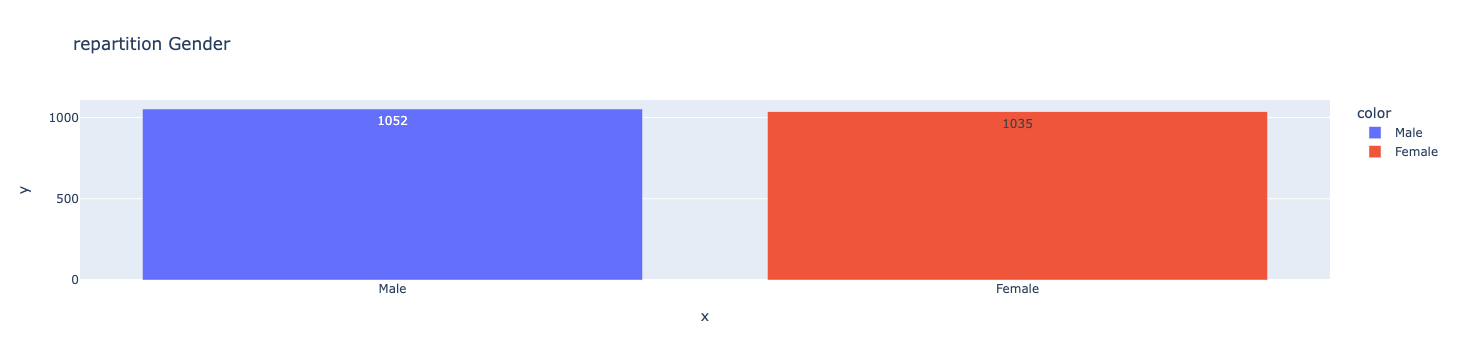

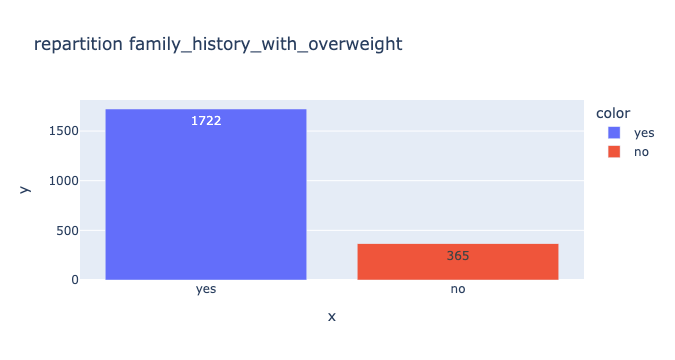

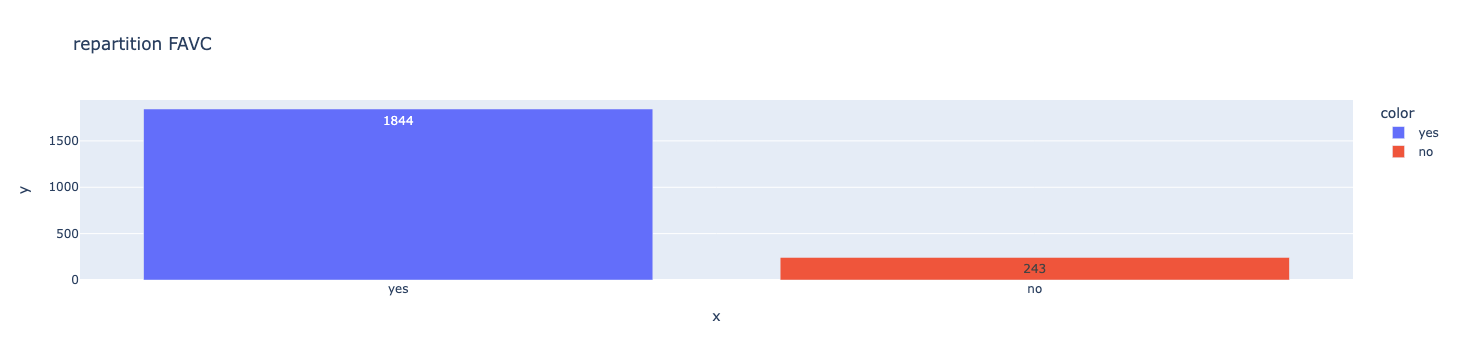

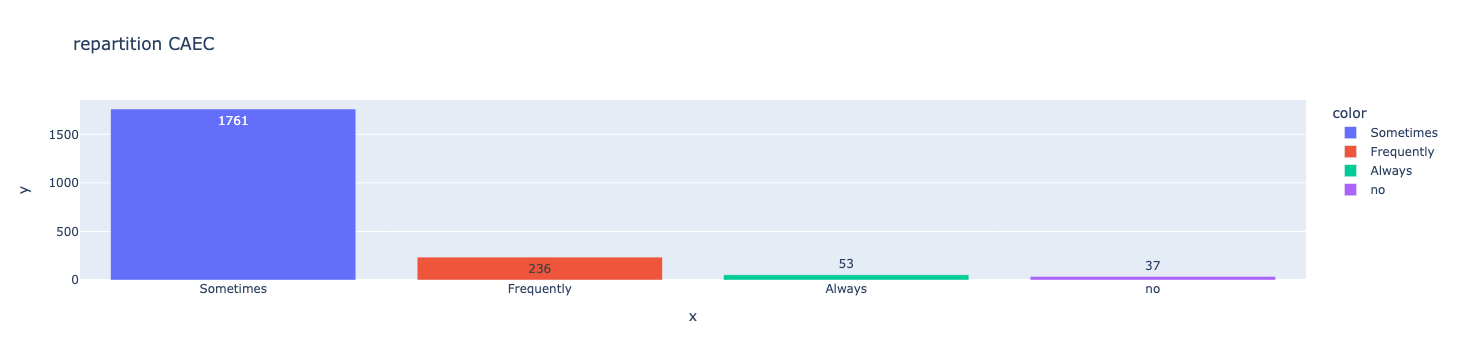

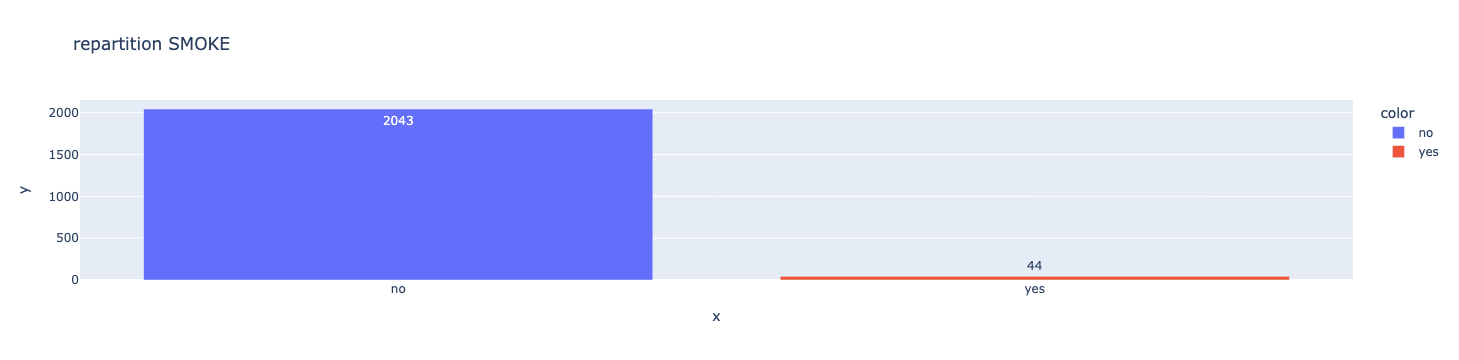

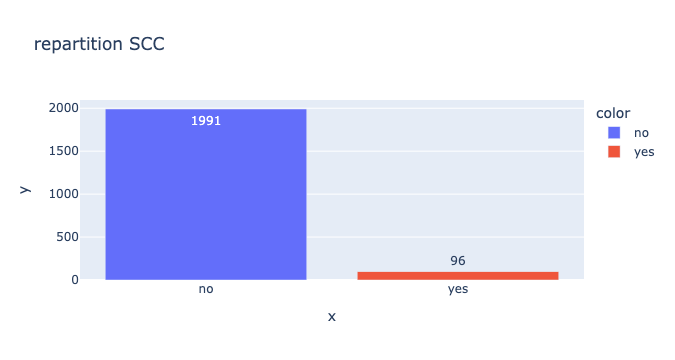

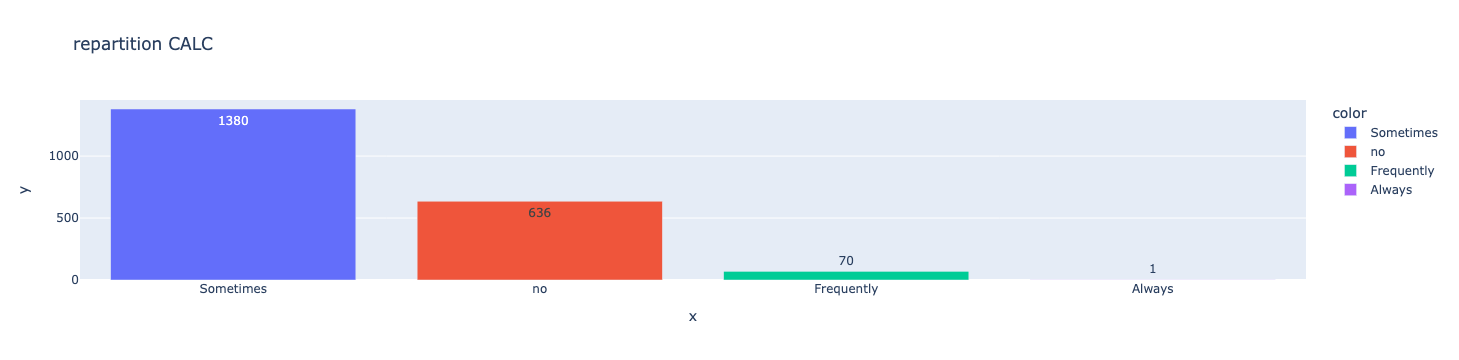

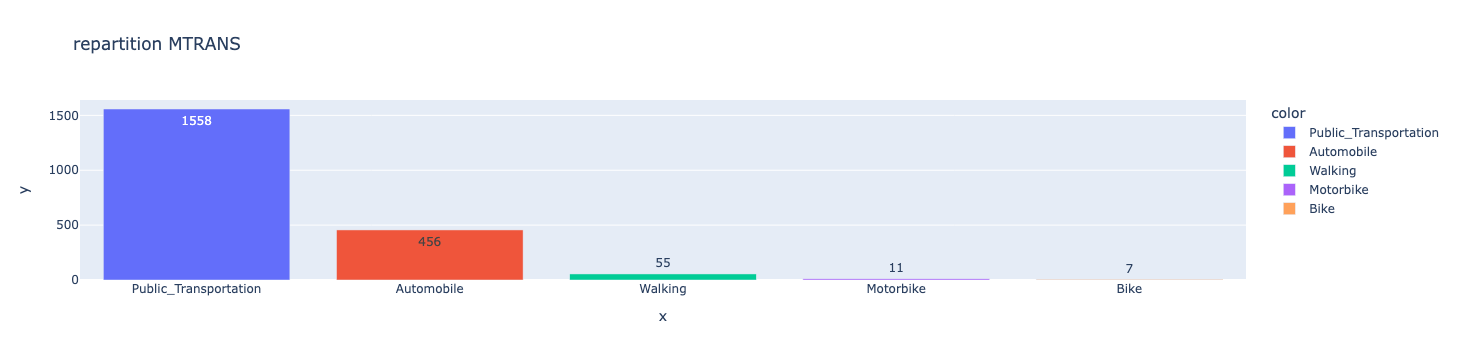

In [16]:
# Diagrammes en barre des variables catégorielles
for col in cat_data.columns :
    countplot_func(col)

In [17]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
uniques = []
for col in cat_data.columns:
  uniques.append(np.unique(df[col]).tolist())
    
# sauvegarde
import joblib as jb 
jb.dump(uniques,'uniques_obeisite.joblib')

['uniques_obeisite.joblib']

###### <font color = 'bisque'> Exploration des variables quantitatives

In [18]:
#description des variables quantitative
quant_data.describe()

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
count,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000,2087.000000
mean,24.353090,1.702674,86.858730,2.421466,2.701179,2.004749,1.012812,0.663035
std,6.368801,0.093186,26.190847,0.534737,0.764614,0.608284,0.853475,0.608153
min,14.000000,1.450000,39.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,19.915937,1.630178,66.000000,2.000000,2.697467,1.590922,0.124505,0.000000
50%,22.847618,1.701584,83.101100,2.396265,3.000000,2.000000,1.000000,0.630866
75%,26.000000,1.769491,108.015907,3.000000,3.000000,2.466193,1.678102,1.000000
max,61.000000,1.980000,173.000000,3.000000,4.000000,3.000000,3.000000,2.000000


<function matplotlib.pyplot.show(close=None, block=None)>

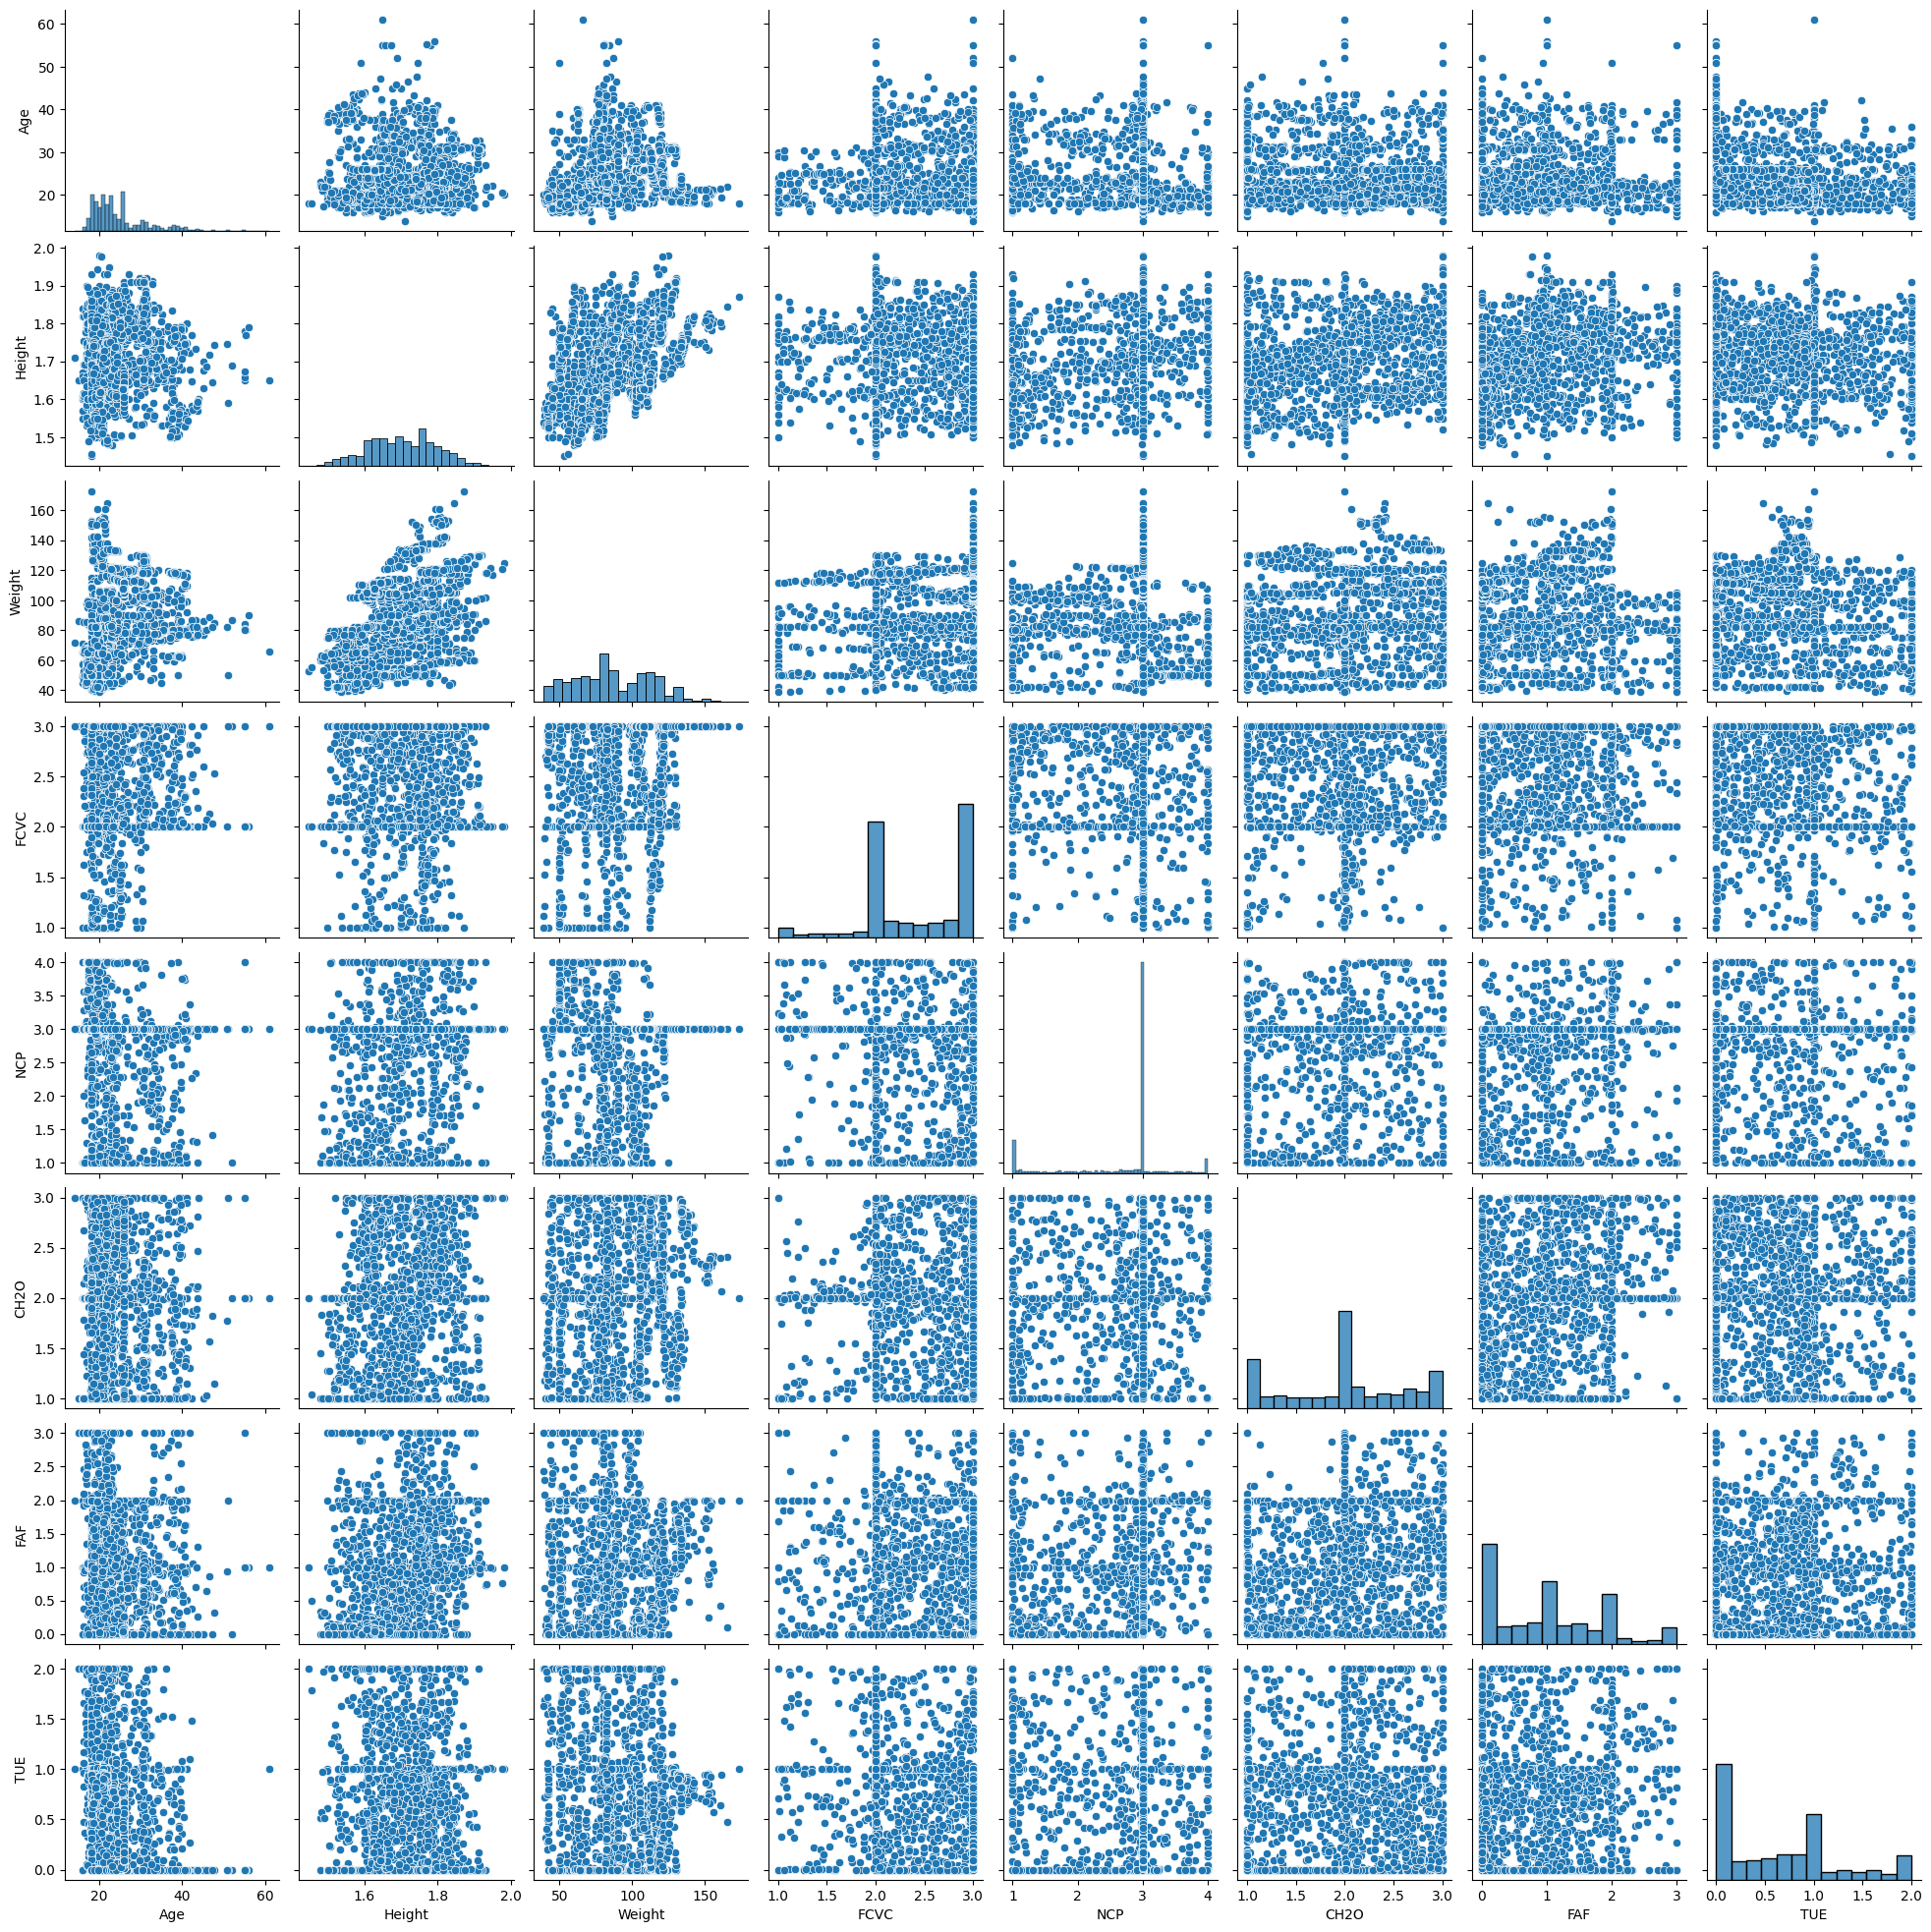

In [19]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show

<Axes: >

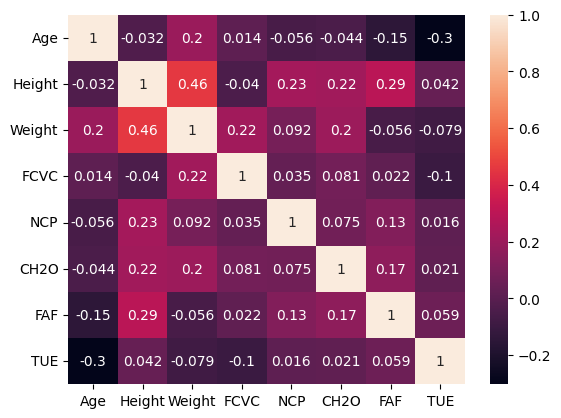

In [20]:
#matrice de correlation
sns.heatmap(quant_data.corr(), annot=True)

In [21]:
# fonction de visualisation des boxplots
def boxplot_func(col):
  plt.figure(figsize=(25,3))
  sns.boxplot(x=df[col])
  plt.title(f"boxplot de {col}")
  plt.show()

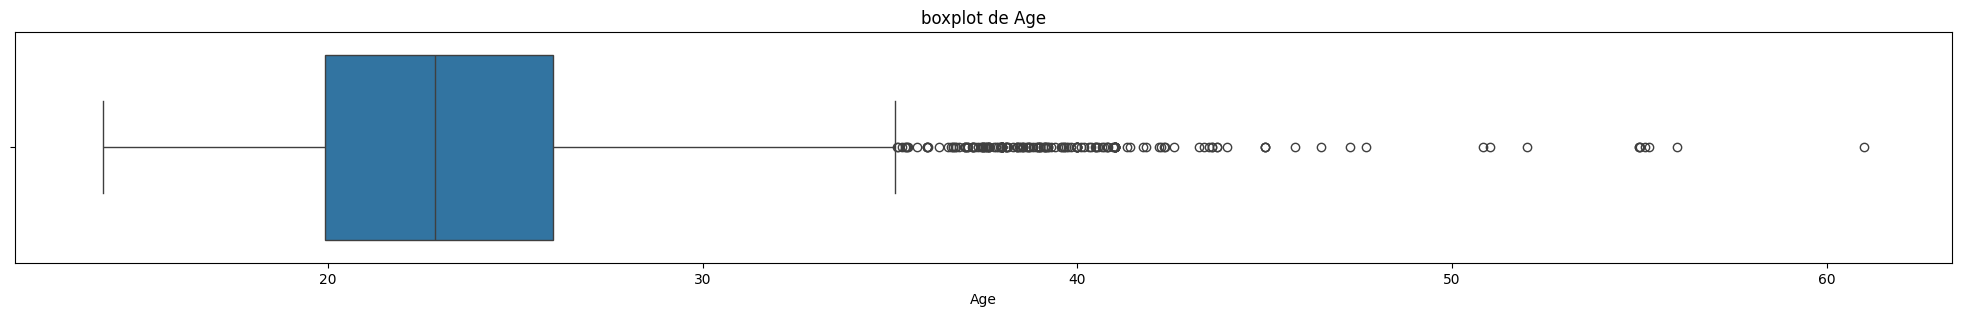

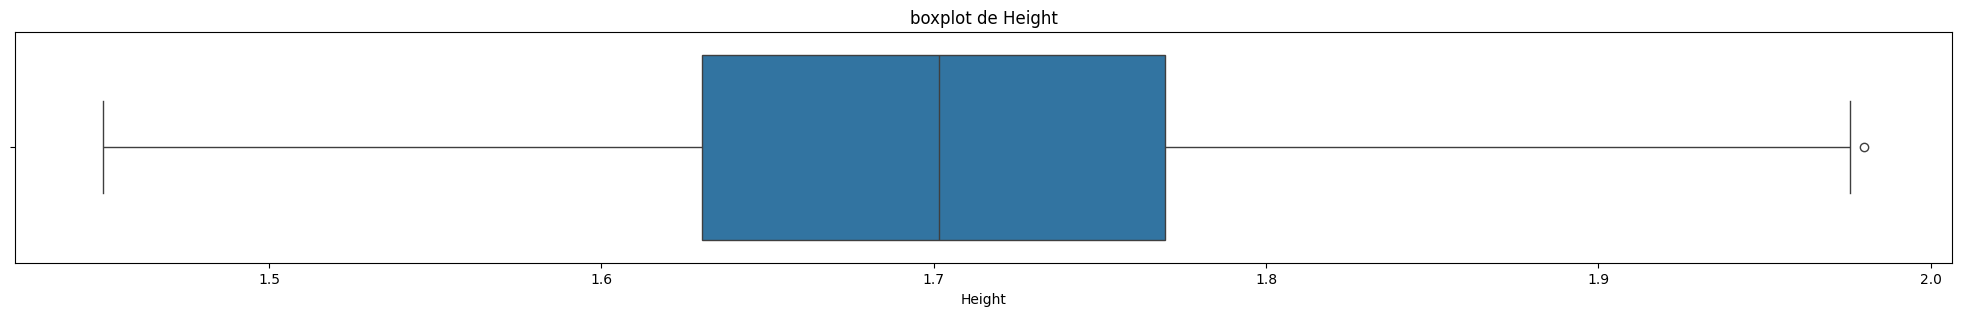

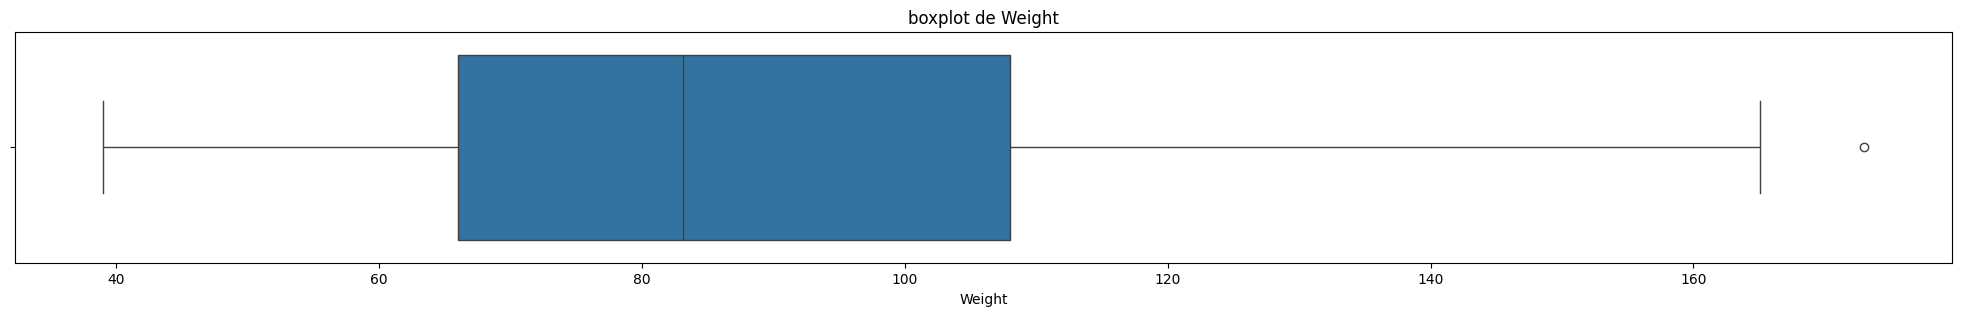

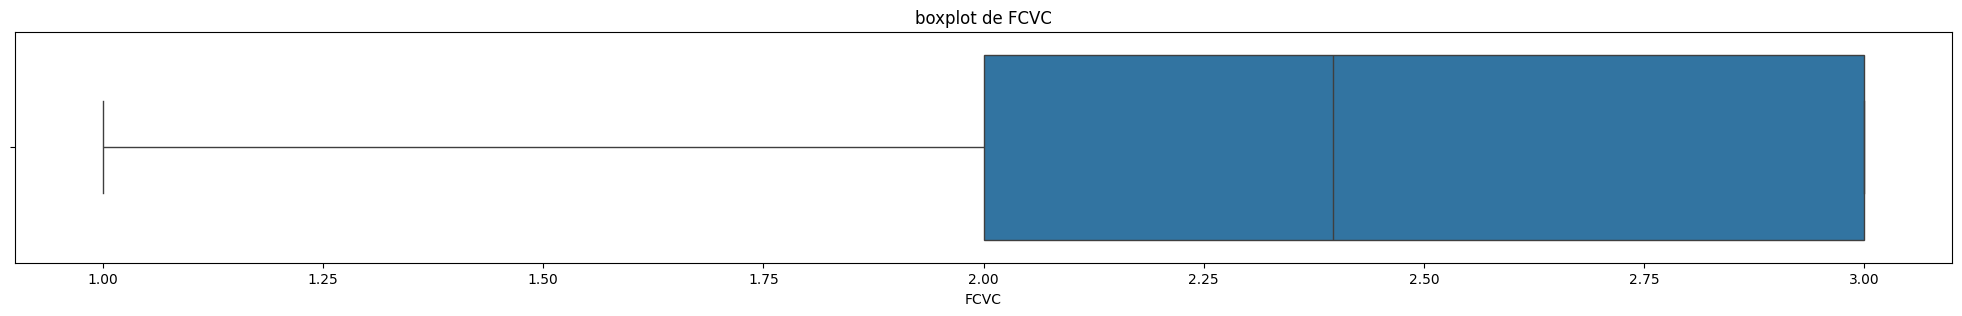

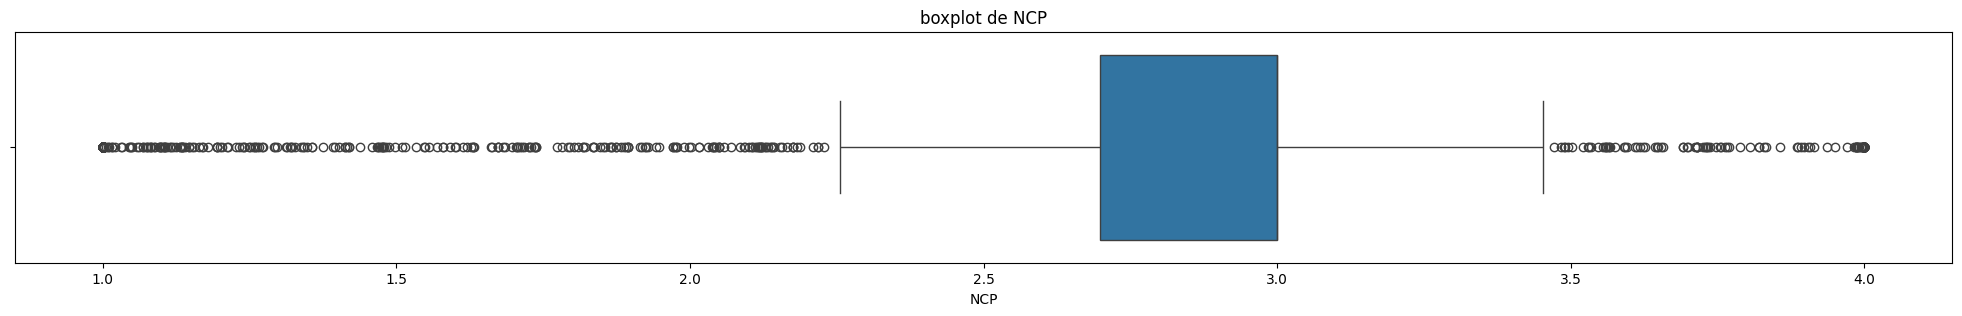

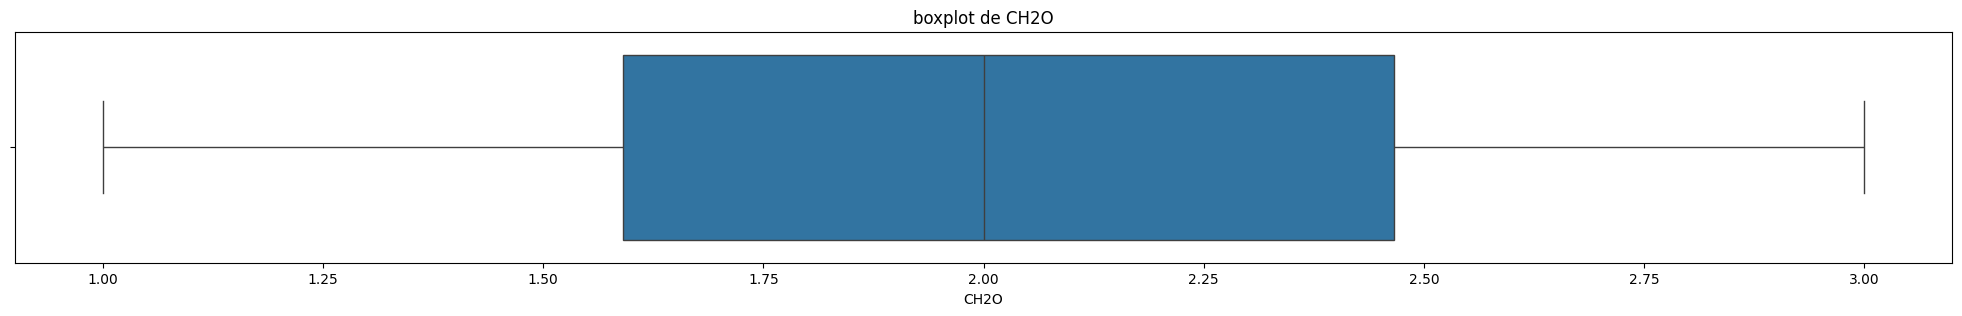

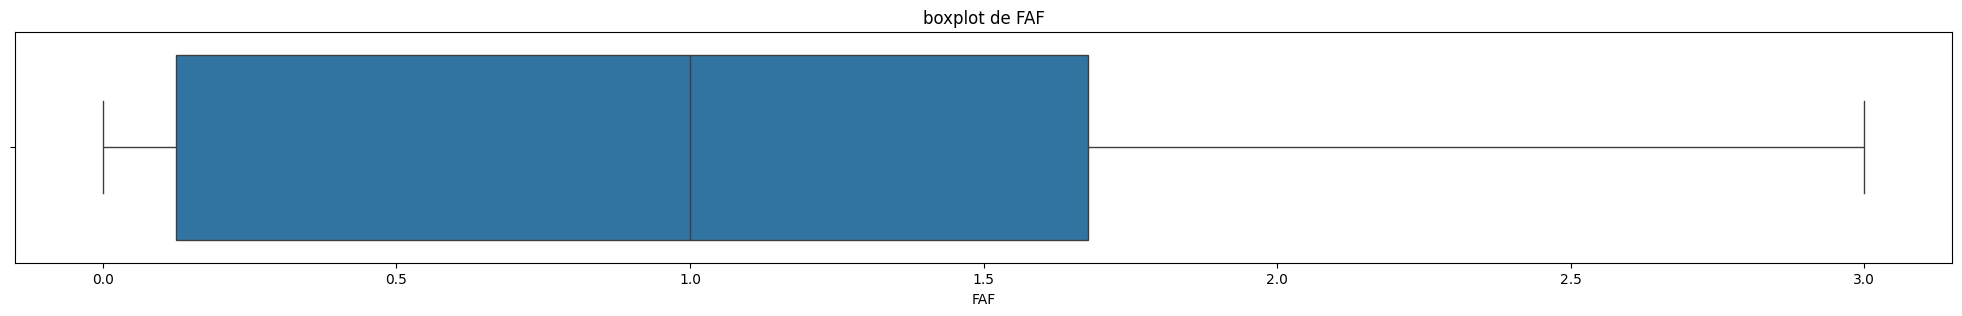

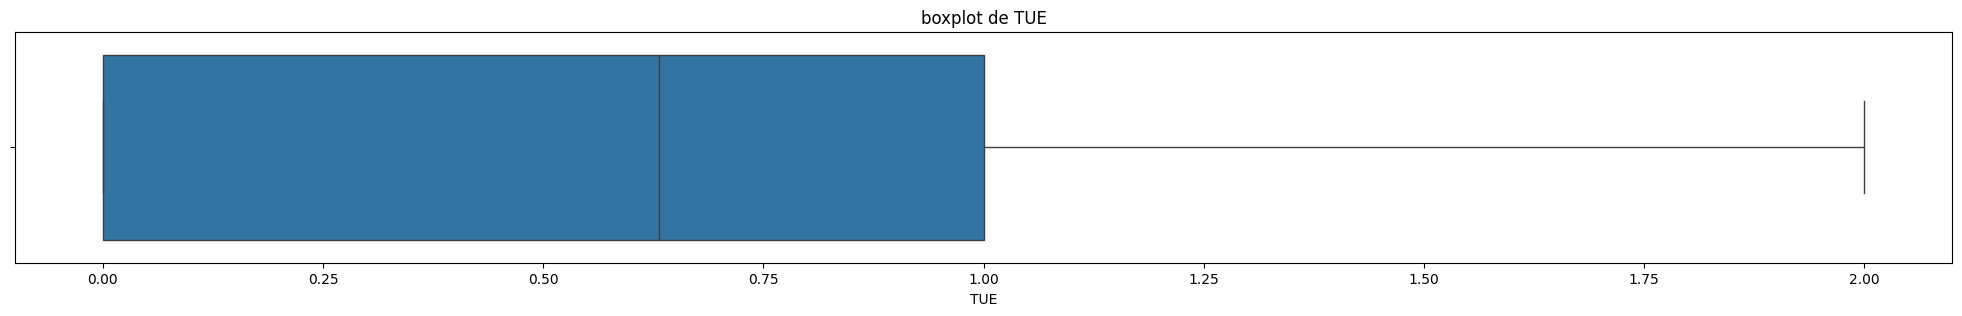

In [22]:
# boxplots des variables quantitatives
for col in quant_data :
    boxplot_func(col)

In [23]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
encoders = []
for i in range(len(cat_data.columns)):
    encoder = LabelEncoder()
    
    encoder.fit(df[cat_data.columns[i]])
    df[cat_data.columns[i]]= encoder.transform(df[cat_data.columns[i]]) 
    # rajouter l'encoder sur la liste encoders
    encoders.append(encoder)

In [24]:
# telechargement de l'encoder
jb.dump(encoders,'encoders_obeisite.joblib')

['encoders_obeisite.joblib']

In [25]:
df.head()

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS
individu1,0,21.0,1.62,64.0,1,0,2.0,3.0,2,0,2.0,0,0.0,1.0,3,3
individu2,0,21.0,1.52,56.0,1,0,3.0,3.0,2,1,3.0,1,3.0,0.0,2,3
individu3,1,23.0,1.80,77.0,1,0,2.0,3.0,2,0,2.0,0,2.0,1.0,1,3
individu4,1,27.0,1.80,87.0,0,0,3.0,3.0,2,0,2.0,0,2.0,0.0,1,4
individu5,1,22.0,1.78,89.8,0,0,2.0,1.0,2,0,2.0,0,0.0,0.0,2,3


In [26]:
X = df.copy().values
X[:3]

array([[ 0.  , 21.  ,  1.62, 64.  ,  1.  ,  0.  ,  2.  ,  3.  ,  2.  ,
         0.  ,  2.  ,  0.  ,  0.  ,  1.  ,  3.  ,  3.  ],
       [ 0.  , 21.  ,  1.52, 56.  ,  1.  ,  0.  ,  3.  ,  3.  ,  2.  ,
         1.  ,  3.  ,  1.  ,  3.  ,  0.  ,  2.  ,  3.  ],
       [ 1.  , 23.  ,  1.8 , 77.  ,  1.  ,  0.  ,  2.  ,  3.  ,  2.  ,
         0.  ,  2.  ,  0.  ,  2.  ,  1.  ,  1.  ,  3.  ]])

In [27]:
# Importer PCA
from sklearn.decomposition import PCA

#Instantier le modèle PCA avec n_components = 2
pca = PCA(n_components=2)

# Entrainer le modèle
features_pca = pca.fit_transform(X)

# Dataframe
df_pca = pd.DataFrame(features_pca,columns=['PCA1','PCA2'])


In [28]:
# Part de variance des 2 composantes
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(99.43)

### <font color='gold'> Kmeans

In [29]:
# Importer KMeans
from sklearn.cluster import KMeans

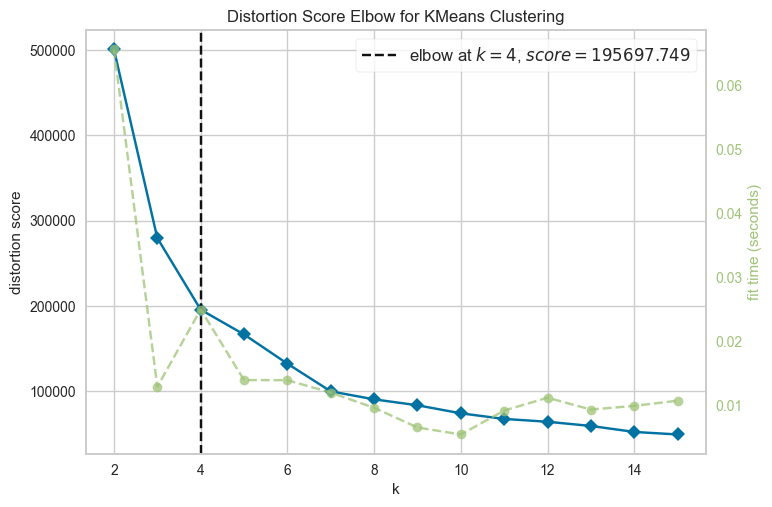

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [30]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'k-means++', max_iter=500,random_state=42)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=15)
# Entrainement
Elbow_M.fit(X)
# Visualiser l'elbow
Elbow_M.show()

In [31]:
# instantier le modèle
kmeans_model = KMeans(n_clusters = 4, init = 'random', max_iter = 500)
# Entrainer le modèle
kmeans_model.fit(X)

,n_clusters,4
,init,'random'
,n_init,'auto'
,max_iter,500
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


#### <font color='teal'> Prédiction

In [32]:
# Prediction de la partition des données
kmeans_partition = kmeans_model.predict(X)
# Afficher la partition
kmeans_partition[: 100]

array([2, 2, 0, 0, 0, 2, 2, 2, 2, 2, 3, 0, 2, 3, 2, 2, 3, 0, 0, 0, 0, 0,
       2, 0, 2, 2, 2, 2, 0, 0, 0, 0, 0, 0, 2, 2, 2, 2, 2, 0, 0, 2, 2, 2,
       0, 2, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 0, 2, 2, 2, 2, 2, 2, 2, 2, 0,
       0, 3, 3, 2, 0, 2, 2, 2, 0, 2, 2, 0, 0, 2, 2, 0, 0, 2, 0, 2, 0, 0,
       2, 0, 0, 2, 0, 2, 2, 0, 2, 2, 0, 2], dtype=int32)

In [33]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

0    709
2    575
3    546
1    257
Name: count, dtype: int64

In [34]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

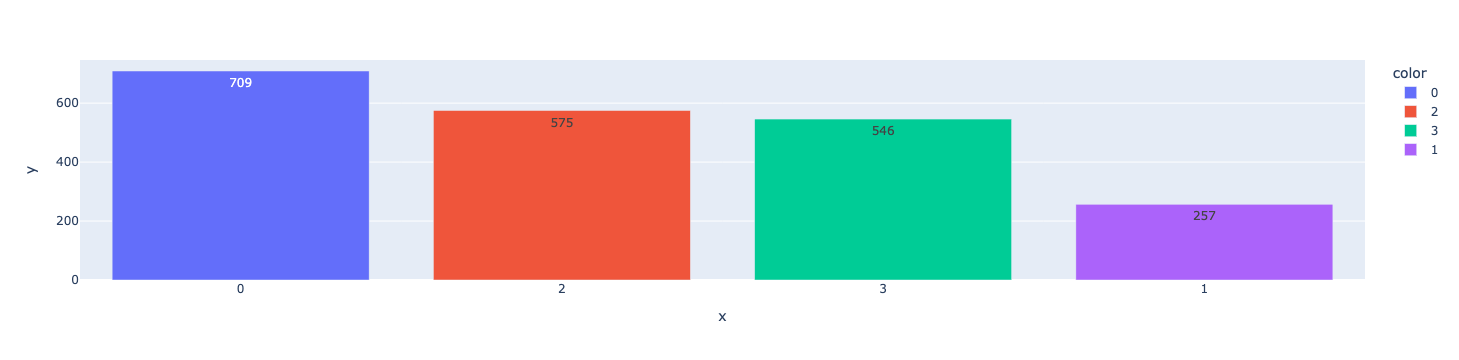

In [35]:
# visualiser le diagramme des nombres d'observations
bar_plot(val)

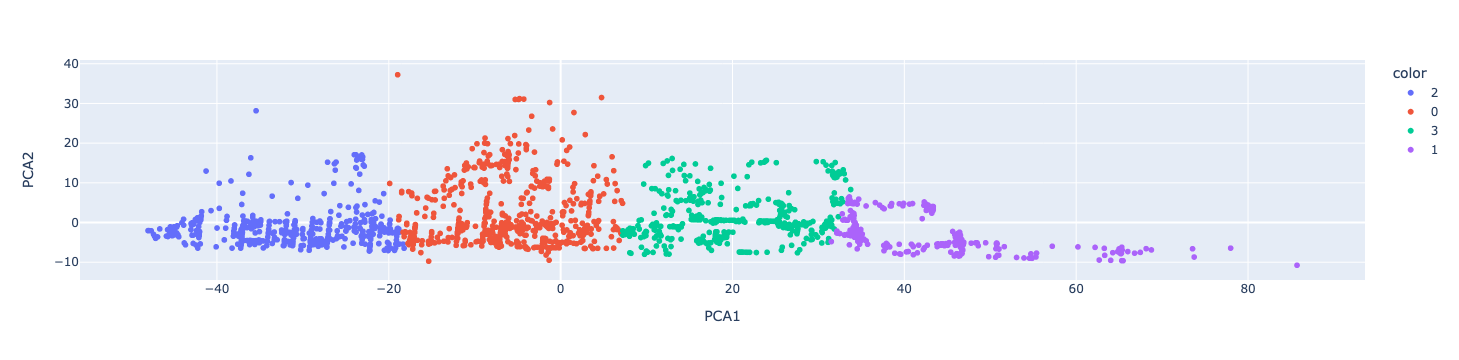

In [36]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PCA1', y = 'PCA2',color=kmeans_partition.astype(str))
fig.show()

<font color = "bisque">Indice de silhouette value de la partition du Kmeans

In [37]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_kmeans = silhouette_score(X,kmeans_partition)
print(f"La silhouette score : {sil_kmeans} ")

La silhouette score : 0.4746969814675721 


### <font color='gold'> CAH

In [38]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import  linkage, dendrogram

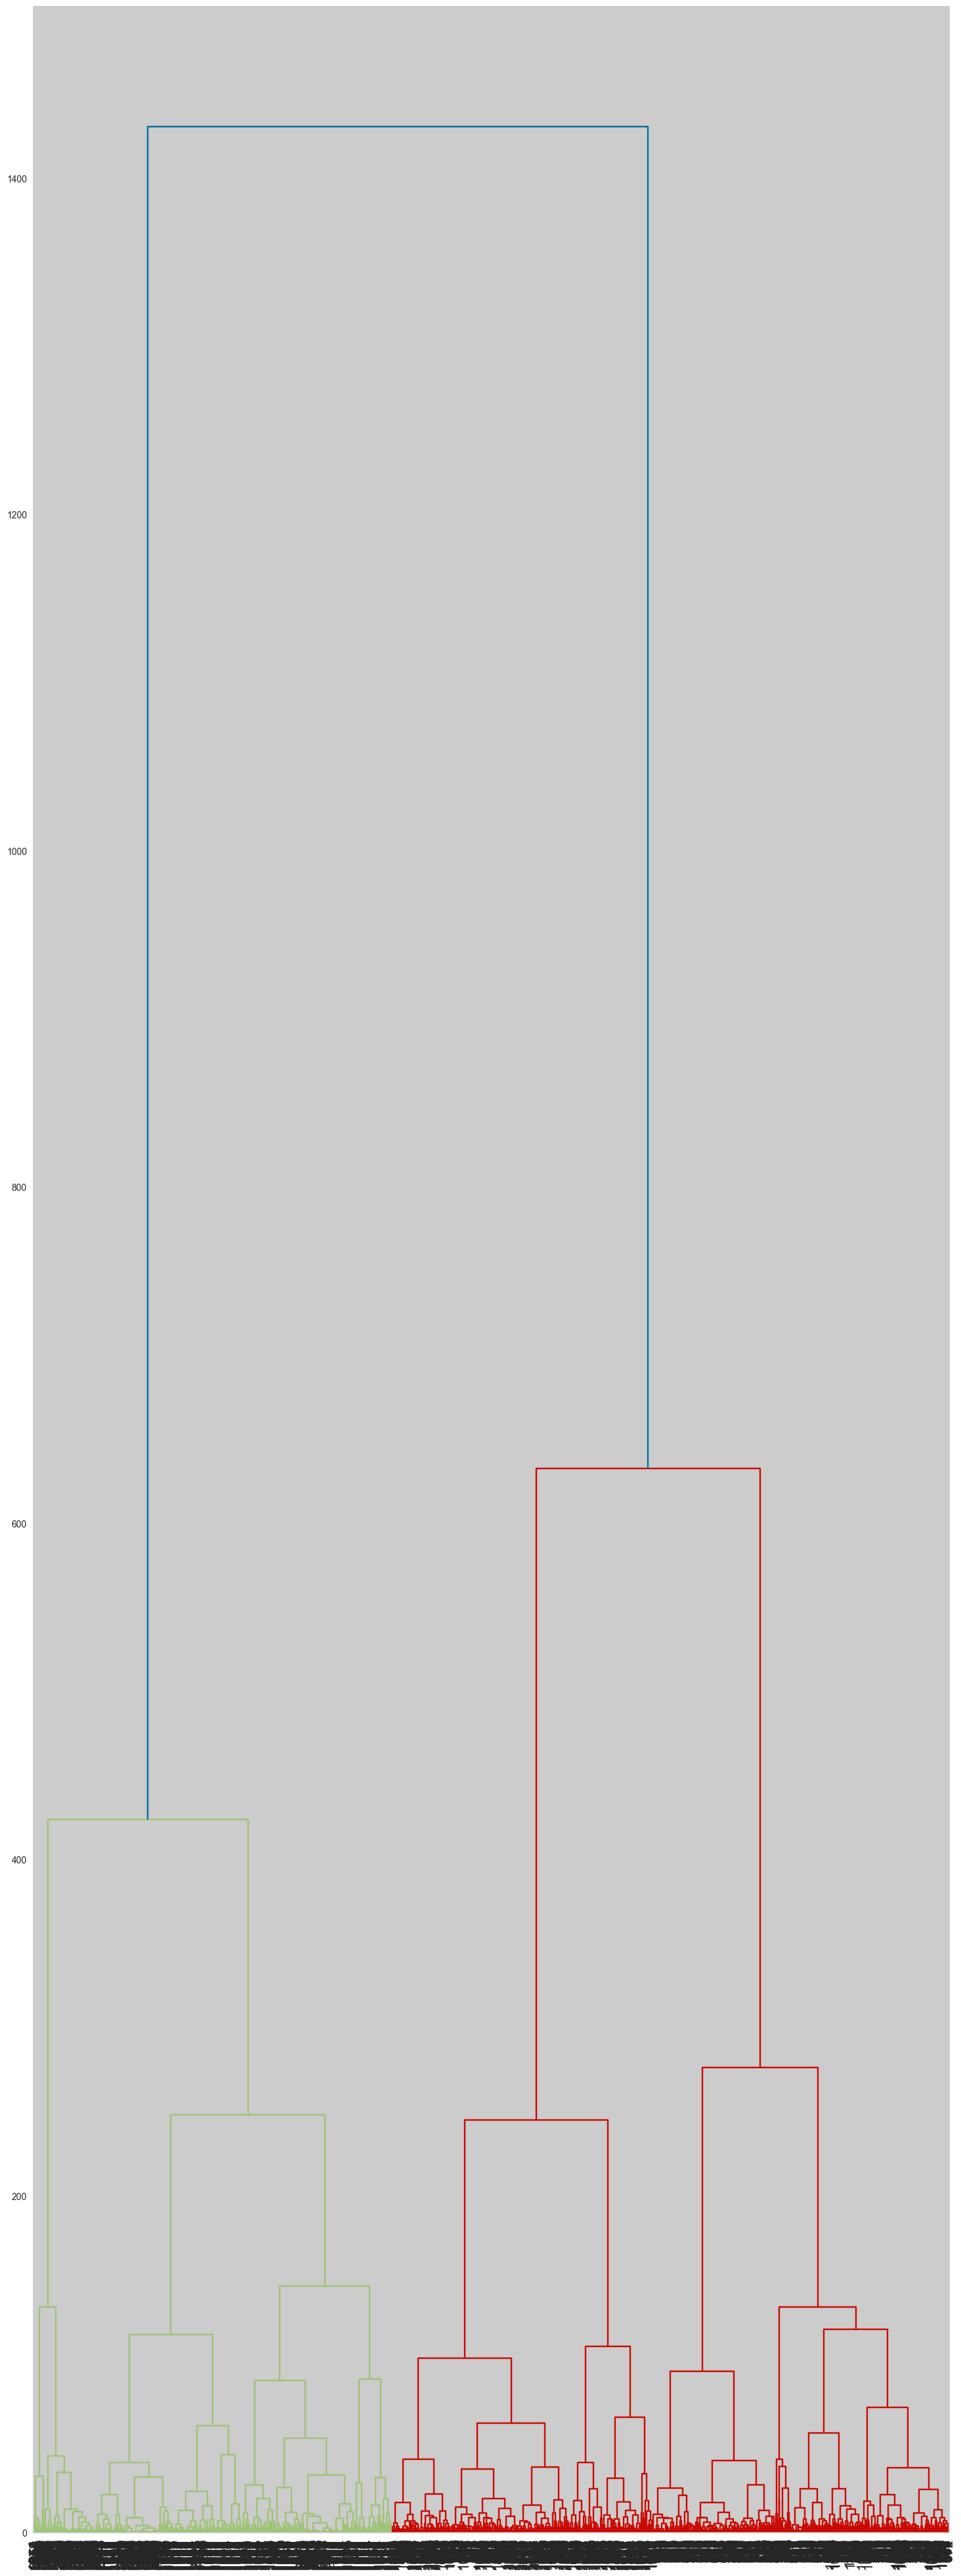

In [39]:
# Visualiser le dendrograme
import matplotlib.pyplot as plt
Z = linkage(X, 'ward')# matrice des liaisons
plt.figure(figsize=(18, 50))
dendro = dendrogram(Z, leaf_font_size=15, orientation = 'top')

In [60]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters =3, linkage = 'ward')
# Entrainer le modèle
cah_model.fit(X)

,n_clusters,3
,metric,'euclidean'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,None
,compute_distances,False


In [61]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(X)
# Afficher la partition
cah_partition[:100]

array([1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 0, 2, 1, 0, 1, 1, 0, 2, 2, 1, 2, 2,
       1, 2, 1, 1, 1, 1, 2, 1, 2, 1, 2, 2, 1, 1, 1, 1, 1, 2, 2, 1, 1, 1,
       2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       2, 0, 0, 1, 2, 1, 1, 1, 2, 1, 1, 2, 2, 1, 1, 2, 2, 1, 2, 1, 2, 2,
       1, 2, 0, 1, 2, 1, 1, 1, 1, 1, 1, 1])

In [62]:
# Nombre d'observations dans chaque classe
val1 = pd.Series(cah_partition).value_counts()
val1

0    818
1    675
2    594
Name: count, dtype: int64

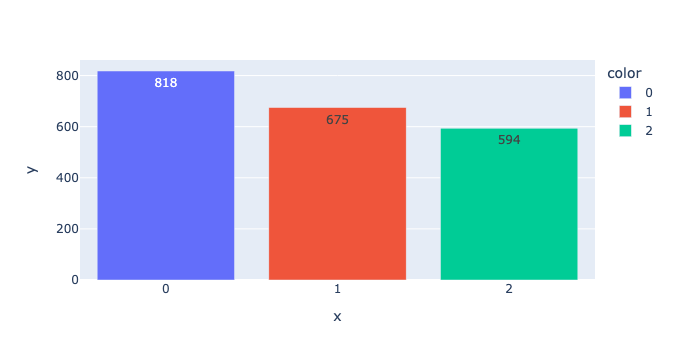

In [63]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

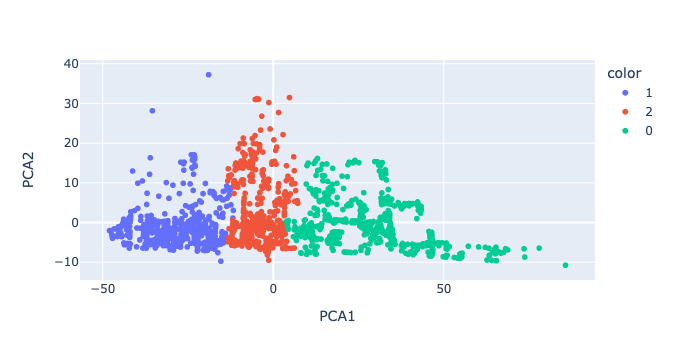

In [64]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PCA1', y = 'PCA2',color=cah_partition.astype(str))
fig.show()

<font color = "bisque">Indice de silhouette value de la partition du CAH

In [80]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_cah = silhouette_score(X,cah_partition)
print(f"La silhouette score : {sil_cah} ")

La silhouette score : 0.4770308995217875 


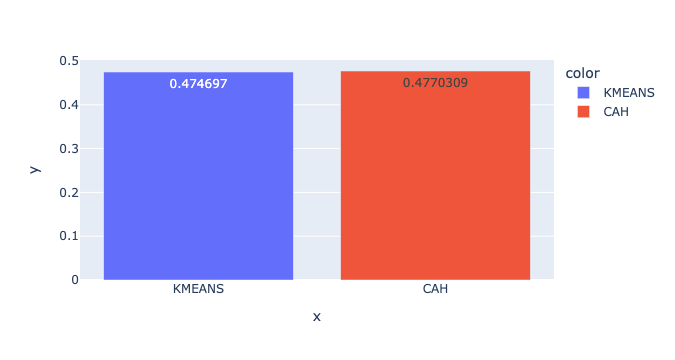

In [81]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [82]:
# les indidivus
cluster_names = []
for i in range(3):
  cluster_names.append(list(df.index[kmeans_partition == i]))

In [83]:
# Les individus de la classe 0
print(cluster_names[0][:10])

['individu3', 'individu4', 'individu5', 'individu12', 'individu18', 'individu19', 'individu20', 'individu21', 'individu22', 'individu24']


#### <font color='gold'> Interpréter les classes

In [84]:
# Profil moyen de chaque classe (sans les anomalies)
profil = df.groupby(kmeans_partition).mean().round(2)
profil["IMC"] = profil["Weight"] / (profil["Height"] ** 2)
profil

,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,IMC
0,0.56,25.93,1.70,80.78,0.87,0.86,2.27,2.53,1.90,0.02,1.99,0.03,1.02,0.59,2.29,2.03,27.951557
1,0.44,23.35,1.79,130.39,1.00,0.99,2.81,2.95,1.98,0.05,2.17,0.00,1.26,0.65,2.00,2.75,40.694735
2,0.31,20.92,1.65,55.30,0.53,0.77,2.38,2.76,1.62,0.02,1.86,0.13,1.13,0.78,2.39,2.57,20.312213
3,0.67,26.39,1.72,107.50,0.99,0.98,2.48,2.74,1.98,0.01,2.10,0.00,0.76,0.64,2.24,2.38,36.337209


In [76]:
import numpy as np
from scipy.spatial.distance import cdist

# Calculer les centroïdes
classes = np.unique(kmeans_partition)
centroides = np.array([X[kmeans_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouveau_client):
    client = np.array(nouveau_client, dtype=float).reshape(1, -1)
    distances = cdist(client, centroides)
    return classes[distances.argmin()]

In [77]:
# Test rapide
print("Classe prédite  :", predire_classe(df.iloc[1].values))
print("Classe réelle du kmean:", kmeans_partition[1])

Classe prédite  : 2
Classe réelle du kmean: 2


In [72]:
# Noms des classes
noms_classes = {
    0: "Corpulence normale",
    1: "Obésité classe II",
    2: "Surpoids",
    3: "Obésité classe III"
}

## Description des clusters obtenus avec le kmean

K-Means a permis d'identifier quatre groupes d'individus présentant des caractéristiques physiques et des habitudes de vie différentes.

- **Cluster 0 – Corpulence normale :** regroupe des individus ayant un IMC moyen de 20,42, correspondant à une corpulence normale.

- **Cluster 1 – Obésité classe II :** regroupe des individus ayant un IMC moyen de 36,52, caractérisé par une corpulence élevée.

- **Cluster 2 – Surpoids :** regroupe des individus ayant un IMC moyen de 28,11, correspondant à une situation de surpoids.

- **Cluster 3 – Obésité classe III :** regroupe des individus ayant un IMC moyen de 40,89, présentant la corpulence moyenne la plus élevée des quatre groupes.

**En conclusion :** ces quatre clusters mettent en évidence différents profils de corpulence au sein du dataset, allant d'une corpulence normale à une obésité de classe III.

In [73]:
# telechargement de l'encoder
jb.dump(kmeans_model,'model_obeisite.joblib')

['model_obeisite.joblib']